# Perbandingan Isolation Forest vs Local Outlier Factor untuk Deteksi Anomali Trafik Serangan
**Dataset:** DDoS Sandbox Dataset (`train_sandbox_v3.csv`, `test_sandbox_v3.csv`)

**Alur penelitian dalam notebook ini**
1. Studi literatur → (di luar notebook)
2. Pengumpulan dataset → bagian 2
3. Eksplorasi dan pemahaman data → bagian 3
4. Preprocessing → bagian 4
5. Penentuan fitur dan data acuan (trafik benign sebagai baseline) + pembagian latih/validasi/uji → bagian 5
6. Model 1 Isolation Forest, Model 2 LOF (pelatihan, tuning, threshold) → bagian 6-7
7. Pengujian pada data uji yang sama → bagian 8
8. Evaluasi kinerja → bagian 8-9
9. Analisis perbandingan → bagian 10-12

**Prinsip desain**
| Aspek | Keputusan | Alasan |
|---|---|---|
| Data acuan (pelatihan) | Hanya trafik `BENIGN` dari file train | Model mempelajari baseline normal (*novelty detection*) |
| Tuning & threshold | Data validasi diambil dari file train (terpisah dari data latih) | File test tidak disentuh sampai evaluasi akhir |
| Evaluasi | File test | Data uji sama untuk kedua model |
| Label | `BENIGN` = 0, selain itu = 1 (serangan) | Deteksi biner normal vs anomali |
| Transformasi | `log1p` bertanda. LOF: + StandardScaler. IF: fitur mentah dan log sama-sama dituning | Fitur trafik sangat miring; pemisahan acak IF terpengaruh |
| `Destination_Port` | Tidak dipakai (diuji di ablasi) | Bisa menjadi jalan pintas bagi model |
| Threshold | Persentil skor benign validasi (FPR target 5%, juga dilaporkan 1%) | Kedua model dibandingkan pada alarm palsu yang sama |
| Stabilitas | 5 seed, rata-rata ± std | Satu kali run bisa kebetulan |

In [15]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, average_precision_score,
                             precision_recall_curve)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

## 1. Konfigurasi

In [16]:
DATA_DIR = "/kaggle/input"      # dicari rekursif
OUT_DIR  = "/kaggle/working"
TRAIN_FILE, TEST_FILE = "train_sandbox_v3.csv", "test_sandbox_v3.csv"
LABEL_COL, BENIGN_LABEL = "Label", "BENIGN"
PORT_COL = "Destination_Port"

N_TRAIN = 20_000      # flow benign untuk melatih model (LOF berat jika terlalu besar)
N_VAL   = 15_000      # validasi (benign + serangan) untuk tuning dan threshold
N_TEST  = 60_000      # sampel data uji, stratifikasi per label
MIN_TYPE_N = 200      # jenis serangan dengan sampel uji >= ini masuk "macro recall mayor"

SEEDS = [42, 7, 123, 2024, 99]
TARGET_FPRS = [0.05, 0.01]      # 0.05 = hasil utama, 0.01 = skenario alarm palsu lebih ketat

LOF_GRID = [{"n_neighbors": k} for k in [10, 20, 35, 50]]
IF_GRID  = [{"n_estimators": n, "max_samples": m, "max_features": f, "log_input": lg}
            for n in [100, 300] for m in [256, 2048] for f in [1.0, 0.5] for lg in [False, True]]

## 2. Pengumpulan dataset

In [17]:
def find(name):
    c = glob.glob(os.path.join(DATA_DIR, "**", name), recursive=True)
    assert c, f"{name} tidak ditemukan di {DATA_DIR}. Tambahkan dataset sebagai Input di Kaggle."
    return c[0]

tr = pd.read_csv(find(TRAIN_FILE), low_memory=False)
te = pd.read_csv(find(TEST_FILE), low_memory=False)
tr.columns, te.columns = tr.columns.str.strip(), te.columns.str.strip()
te = te[tr.columns]                      # urutan kolom di file test berbeda dari train
tr[LABEL_COL] = tr[LABEL_COL].astype(str).str.strip()
te[LABEL_COL] = te[LABEL_COL].astype(str).str.strip()
print("train:", tr.shape, "| test:", te.shape)

train: (821063, 78) | test: (351895, 78)


## 3. Eksplorasi dan pemahaman data
Memeriksa kolom, tipe data, label, jumlah data, distribusi kelas, nilai kosong/tak hingga, duplikat, dan tumpang tindih train-test.

In [18]:
print("Tipe data kolom:", tr.dtypes.value_counts().to_dict())
dist = pd.concat({"train": tr[LABEL_COL].value_counts(), "test": te[LABEL_COL].value_counts()}, axis=1).fillna(0).astype(int)
dist["porsi_train_%"] = (dist["train"] / dist["train"].sum() * 100).round(2)
dist["porsi_test_%"] = (dist["test"] / dist["test"].sum() * 100).round(2)
display(dist)

feat_cols = [c for c in tr.columns if c != LABEL_COL]
for name, d in [("train", tr), ("test", te)]:
    num = d[feat_cols].select_dtypes("number")
    print(f"[{name}] sel kosong={int(d.isna().sum().sum())}, sel tak hingga={int(np.isinf(num).sum().sum())}, "
          f"baris duplikat={d.duplicated().mean():.2%}")

ov = te[feat_cols].merge(tr[feat_cols].drop_duplicates(), how="left", indicator=True)
print(f"Baris test yang SAMA PERSIS dengan baris di train: {(ov['_merge']=='both').mean():.2%}")
print("Catatan: porsi kelas train dan test hampir identik, indikasi pembagian acak dari satu kumpulan data.")

Tipe data kolom: {dtype('float64'): 72, dtype('int64'): 5, dtype('O'): 1}


,train,test,porsi_train_%,porsi_test_%
Label,,,,
BENIGN,370623,159295,45.14,45.27
DoS Hulk,310126,132394,37.77,37.62
DoS slowloris,128612,55180,15.66,15.68
GoldenEye,11519,4947,1.40,1.41
Slowloris,105,45,0.01,0.01
Hulken,78,34,0.01,0.01


[train] sel kosong=0, sel tak hingga=0, baris duplikat=2.52%
[test] sel kosong=0, sel tak hingga=0, baris duplikat=1.86%
Baris test yang SAMA PERSIS dengan baris di train: 3.45%
Catatan: porsi kelas train dan test hampir identik, indikasi pembagian acak dari satu kumpulan data.


,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Flow_Packets_Sec,SYN_Flag_Count,ACK_Flag_Count
Label,,,,,,
BENIGN,31298.0,2.0,2.0,151435.000000,0.0,0.0
DoS Hulk,3179289.0,7.0,1.0,2.489140,1.0,0.0
DoS slowloris,55540088.0,8.0,1.0,0.169346,1.0,0.0
GoldenEye,46259.0,4.0,3.0,40.251167,0.0,0.0
Hulken,19809391.0,2565.0,1138.0,194.658625,0.0,0.0
Slowloris,11093.0,2.0,1.0,270.440819,0.0,0.0


Port tujuan terbanyak per label (train):
  BENIGN          {53: 150361, 443: 98597, 80: 35543, 123: 3607}
  DoS Hulk        {80: 310126}
  DoS slowloris   {80: 128612}
  GoldenEye       {30666: 7549, 55260: 3, 55838: 3, 45064: 3}
  Hulken          {30666: 18, 42628: 1, 43310: 1, 38856: 1}
  Slowloris       {30666: 105}


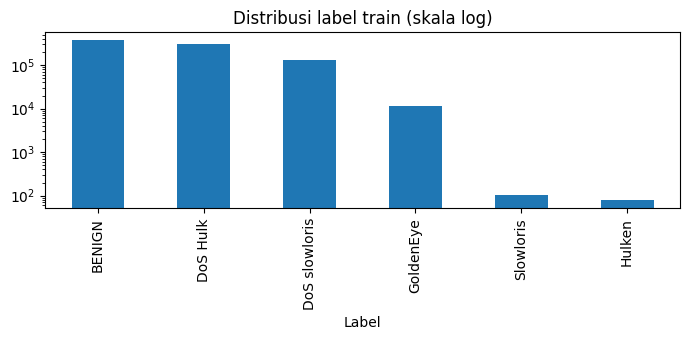

In [19]:
cols_eda = ["Flow_Duration", "Total_Fwd_Packets", "Total_Backward_Packets", "Flow_Packets_Sec", "SYN_Flag_Count", "ACK_Flag_Count"]
display(tr.groupby(LABEL_COL)[cols_eda].median())
print("Port tujuan terbanyak per label (train):")
for l, g in tr.groupby(LABEL_COL):
    print(f"  {l:15s}", g[PORT_COL].value_counts().head(4).to_dict())
dist["train"].plot(kind="bar", figsize=(7, 3.5), logy=True, title="Distribusi label train (skala log)")
plt.tight_layout(); plt.show()

## 4. Preprocessing
- Tidak ada NaN/inf di dataset ini (diperiksa di atas), tetapi tetap ditangani jika muncul.
- Semua fitur sudah numerik; kolom konstan dibuang.
- Nilai negatif pada beberapa kolom (mis. `Flow_Duration`, `Init_Win_bytes_*`) adalah artefak ekstraksi CICFlowMeter; dipertahankan dan ditangani oleh `log1p` bertanda.
- Duplikat hanya dibuang dari data latih.

In [20]:
const = [c for c in feat_cols if tr[c].nunique() <= 1]
FEATS = [c for c in feat_cols if c not in const]
print("Kolom konstan dibuang:", const)

def to_array(d):
    X = d[FEATS].replace([np.inf, -np.inf], np.nan).fillna(0)
    return X.values.astype("float32")

X_TR, X_TE = to_array(tr), to_array(te)
LAB_TR, LAB_TE = tr[LABEL_COL].values, te[LABEL_COL].values
COL_IDX = {c: i for i, c in enumerate(FEATS)}
IDX_NOPORT = [i for c, i in COL_IDX.items() if c != PORT_COL]
IDX_WITHPORT = list(range(len(FEATS)))
print("Fitur dipakai:", len(IDX_NOPORT), "(tanpa Destination_Port)")

Kolom konstan dibuang: ['Fwd_URG_Flags', 'Bwd_URG_Flags', 'CWE_Flag_Count']
Fitur dipakai: 73 (tanpa Destination_Port)


## 5. Penentuan fitur dan data acuan; pembagian data
- **Data acuan (latih):** sampel trafik `BENIGN` dari file train, duplikat dibuang.
- **Validasi:** sampel stratifikasi dari baris train yang **tidak** dipakai melatih (berisi benign dan serangan), untuk tuning dan threshold.
- **Uji:** sampel stratifikasi dari file test.

In [21]:
def slog(a): return np.sign(a) * np.log1p(np.abs(a))

def make_split(seed):
    rs = np.random.RandomState(seed)
    ben = np.where(LAB_TR == BENIGN_LABEL)[0]
    fit = rs.choice(ben, min(N_TRAIN, len(ben)), replace=False)
    fit = fit[~pd.DataFrame(X_TR[fit]).duplicated().values]
    rest = np.setdiff1d(np.arange(len(X_TR)), fit)
    val, _ = train_test_split(rest, train_size=N_VAL, stratify=LAB_TR[rest], random_state=seed)
    tst, _ = train_test_split(np.arange(len(X_TE)), train_size=N_TEST, stratify=LAB_TE, random_state=seed)
    return fit, val, tst

fit, val, tst = make_split(SEEDS[0])
print(f"Latih (benign): {len(fit)} | Validasi: {len(val)} (serangan {(LAB_TR[val]!=BENIGN_LABEL).mean():.1%}) "
      f"| Uji: {len(tst)} (serangan {(LAB_TE[tst]!=BENIGN_LABEL).mean():.1%})")

Latih (benign): 19684 | Validasi: 15000 (serangan 56.2%) | Uji: 60000 (serangan 54.7%)


## 6. Fungsi eksperimen
Satu *seed*: bangun split → tuning IF dan LOF di validasi (PR-AUC) → threshold dari skor benign validasi → prediksi pada data uji yang sama → metrik.

In [22]:
def build(name, params, seed):
    if name == "IF":
        params = {k: v for k, v in params.items() if k != "log_input"}
        return IsolationForest(random_state=seed, n_jobs=-1, **params)
    return LocalOutlierFactor(novelty=True, n_jobs=-1, **params)

def metrics(y, pred, score, lab):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    per = pd.Series(pred[y == 1]).groupby(lab[y == 1])
    rec, cnt = per.mean(), per.size()
    major = rec[cnt >= MIN_TYPE_N]
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC_AUC": roc_auc_score(y, score), "PR_AUC": average_precision_score(y, score),
            "FPR": fp / (fp + tn), "Macro_Recall_Mayor": major.mean(),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}, rec

def run_seed(seed, cols=None, verbose=True):
    cols = IDX_NOPORT if cols is None else cols
    fit, val, tst = make_split(seed)
    Xf, Xv, Xt = (X_TR[fit][:, cols].astype("float64"), X_TR[val][:, cols].astype("float64"),
                  X_TE[tst][:, cols].astype("float64"))
    sc = StandardScaler().fit(slog(Xf))
    data = {"IF_raw": (Xf, Xv, Xt), "IF_log": (slog(Xf), slog(Xv), slog(Xt)),
            "LOF": (sc.transform(slog(Xf)), sc.transform(slog(Xv)), sc.transform(slog(Xt)))}
    def pick(name, p):
        if name == "IF": return data["IF_log"] if p.get("log_input") else data["IF_raw"]
        return data["LOF"]
    lab_v, lab_t = LAB_TR[val], LAB_TE[tst]
    yv, yt = (lab_v != BENIGN_LABEL).astype(int), (lab_t != BENIGN_LABEL).astype(int)
    rows, per_type, extra = [], {}, {}
    for name, grid in [("IF", IF_GRID), ("LOF", LOF_GRID)]:
        best = None
        for p in grid:
            A, B, C = pick(name, p)
            ap = average_precision_score(yv, -build(name, p, seed).fit(A).score_samples(B))
            if best is None or ap > best[0]: best = (ap, p)
        A, B, C = pick(name, best[1])
        t0 = time.time(); model = build(name, best[1], seed).fit(A); t_fit = time.time() - t0
        s_v = -model.score_samples(B)
        t0 = time.time(); s_t = -model.score_samples(C); t_pred = time.time() - t0
        for fpr in TARGET_FPRS:
            thr = np.percentile(s_v[yv == 0], 100 * (1 - fpr))
            pred = (s_t > thr).astype(int)
            m, rec = metrics(yt, pred, s_t, lab_t)
            m.update({"Model": name, "seed": seed, "FPR_target": fpr, "param_terbaik": str(best[1]),
                      "Waktu_latih_s": t_fit, "Waktu_prediksi_s": t_pred})
            rows.append(m)
            if fpr == TARGET_FPRS[0]:
                per_type[name] = rec
                extra[name] = {"score": s_t, "pred": pred, "thr": thr}
        if verbose:
            r = [x for x in rows if x["Model"] == name and x["FPR_target"] == TARGET_FPRS[0]][-1]
            print(f"seed {seed} | {name:3s} | {best[1]} | F1={r['F1']:.3f} PR-AUC={r['PR_AUC']:.3f} "
                  f"MacroMayor={r['Macro_Recall_Mayor']:.3f} ({t_fit:.1f}s/{t_pred:.1f}s)")
    extra["lab_t"], extra["tst"] = lab_t, tst
    return rows, per_type, extra

## 7. Menjalankan eksperimen (beberapa seed)

In [23]:
all_rows, all_pt, first_extra = [], [], None
for seed in SEEDS:
    rows, pt, extra = run_seed(seed)
    all_rows += rows
    all_pt.append(pd.DataFrame(pt).assign(seed=seed))
    if first_extra is None: first_extra = extra
results = pd.DataFrame(all_rows)
per_type_all = pd.concat(all_pt)

seed 42 | IF  | {'n_estimators': 300, 'max_samples': 2048, 'max_features': 0.5, 'log_input': True} | F1=0.954 PR-AUC=0.983 MacroMayor=0.874 (1.1s/1.9s)
seed 42 | LOF | {'n_neighbors': 50} | F1=0.932 PR-AUC=0.964 MacroMayor=0.897 (2.1s/6.4s)
seed 7 | IF  | {'n_estimators': 100, 'max_samples': 2048, 'max_features': 0.5, 'log_input': True} | F1=0.949 PR-AUC=0.985 MacroMayor=0.744 (0.4s/0.7s)
seed 7 | LOF | {'n_neighbors': 10} | F1=0.981 PR-AUC=0.972 MacroMayor=0.972 (1.9s/5.7s)
seed 123 | IF  | {'n_estimators': 300, 'max_samples': 2048, 'max_features': 1.0, 'log_input': True} | F1=0.945 PR-AUC=0.983 MacroMayor=0.815 (1.0s/2.0s)
seed 123 | LOF | {'n_neighbors': 50} | F1=0.959 PR-AUC=0.977 MacroMayor=0.951 (2.1s/6.4s)
seed 2024 | IF  | {'n_estimators': 300, 'max_samples': 2048, 'max_features': 1.0, 'log_input': True} | F1=0.971 PR-AUC=0.984 MacroMayor=0.901 (1.0s/1.9s)
seed 2024 | LOF | {'n_neighbors': 50} | F1=0.891 PR-AUC=0.970 MacroMayor=0.761 (2.1s/6.4s)
seed 99 | IF  | {'n_estimators':

## 8. Hasil evaluasi pada data uji
Rata-rata ± standar deviasi dari seluruh seed. Data uji berisi sekitar separuh serangan, jadi Accuracy bisa dibaca langsung, tetapi tetap bandingkan dengan F1 dan PR-AUC.

In [24]:
MAIN = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC", "FPR", "Macro_Recall_Mayor",
        "Waktu_latih_s", "Waktu_prediksi_s"]
def table(fpr):
    a = results[results.FPR_target == fpr].groupby("Model")[MAIN].agg(["mean", "std"])
    return pd.DataFrame({c: a[c]["mean"].map("{:.3f}".format) + " ± " + a[c]["std"].map("{:.3f}".format) for c in MAIN}).T

print(f"=== Hasil utama (FPR target {TARGET_FPRS[0]:.0%}) ===")
summary = table(TARGET_FPRS[0]); display(summary)
for f in TARGET_FPRS[1:]:
    print(f"=== Skenario alarm palsu lebih ketat (FPR target {f:.0%}) ===")
    display(table(f))
print("Parameter terpilih per seed:")
display(results[results.FPR_target == TARGET_FPRS[0]].pivot(index="seed", columns="Model", values="param_terbaik"))

=== Hasil utama (FPR target 5%) ===


Model,IF,LOF
Accuracy,0.951 ± 0.010,0.940 ± 0.034
Precision,0.960 ± 0.002,0.959 ± 0.005
Recall,0.951 ± 0.020,0.931 ± 0.062
F1,0.955 ± 0.010,0.944 ± 0.034
ROC_AUC,0.988 ± 0.002,0.981 ± 0.003
PR_AUC,0.982 ± 0.003,0.971 ± 0.005
FPR,0.048 ± 0.003,0.048 ± 0.005
Macro_Recall_Mayor,0.843 ± 0.064,0.907 ± 0.086
Waktu_latih_s,0.899 ± 0.306,2.063 ± 0.106
Waktu_prediksi_s,1.680 ± 0.571,6.259 ± 0.289


=== Skenario alarm palsu lebih ketat (FPR target 1%) ===


Model,IF,LOF
Accuracy,0.802 ± 0.072,0.623 ± 0.042
Precision,0.987 ± 0.003,0.975 ± 0.008
Recall,0.647 ± 0.132,0.320 ± 0.077
F1,0.776 ± 0.088,0.477 ± 0.094
ROC_AUC,0.988 ± 0.002,0.981 ± 0.003
PR_AUC,0.982 ± 0.003,0.971 ± 0.005
FPR,0.010 ± 0.001,0.009 ± 0.001
Macro_Recall_Mayor,0.500 ± 0.064,0.168 ± 0.054
Waktu_latih_s,0.899 ± 0.306,2.063 ± 0.106
Waktu_prediksi_s,1.680 ± 0.571,6.259 ± 0.289


Parameter terpilih per seed:


Model,IF,LOF
seed,,
7,"{'n_estimators': 100, 'max_samples': 2048, 'ma...",{'n_neighbors': 10}
42,"{'n_estimators': 300, 'max_samples': 2048, 'ma...",{'n_neighbors': 50}
99,"{'n_estimators': 300, 'max_samples': 2048, 'ma...",{'n_neighbors': 50}
123,"{'n_estimators': 300, 'max_samples': 2048, 'ma...",{'n_neighbors': 50}
2024,"{'n_estimators': 300, 'max_samples': 2048, 'ma...",{'n_neighbors': 50}


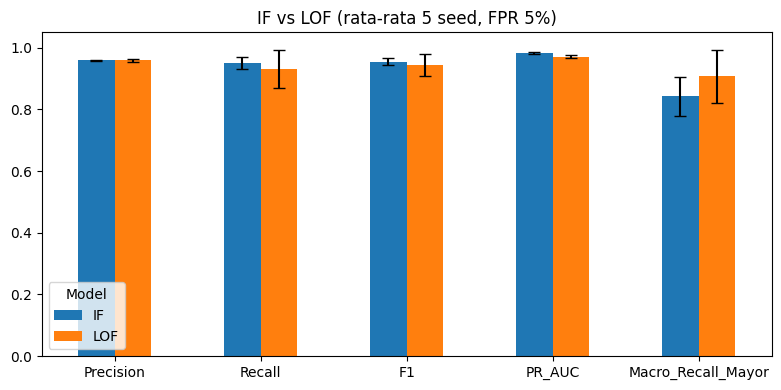

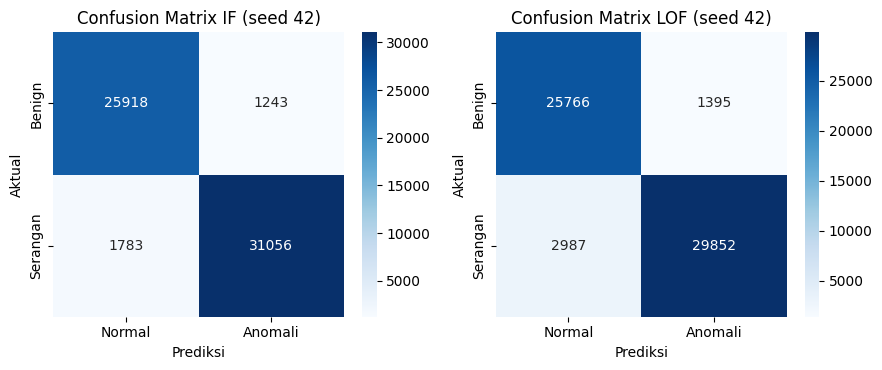

In [25]:
agg = results[results.FPR_target == TARGET_FPRS[0]].groupby("Model")[["Precision", "Recall", "F1", "PR_AUC", "Macro_Recall_Mayor"]].agg(["mean", "std"])
mean, std = agg.xs("mean", axis=1, level=1), agg.xs("std", axis=1, level=1)
ax = mean.T.plot(kind="bar", yerr=std.T, capsize=4, figsize=(8, 4), rot=0)
ax.set_ylim(0, 1.05); ax.set_title(f"IF vs LOF (rata-rata {len(SEEDS)} seed, FPR {TARGET_FPRS[0]:.0%})")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
y_true = (first_extra["lab_t"] != BENIGN_LABEL).astype(int)
for ax, name in zip(axes, ["IF", "LOF"]):
    sns.heatmap(confusion_matrix(y_true, first_extra[name]["pred"]), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Anomali"], yticklabels=["Benign", "Serangan"])
    ax.set_title(f"Confusion Matrix {name} (seed {SEEDS[0]})"); ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
plt.tight_layout(); plt.show()

## 9. Recall per jenis serangan
Jenis serangan dengan sampel uji sangat sedikit (kolom `n_uji` kecil) hasilnya tidak stabil; jangan dijadikan kesimpulan.

,IF,LOF,n_uji
DoS Hulk,0.944,0.985,22574
DoS slowloris,1.000,0.803,9408
GoldenEye,0.584,0.933,843
Slowloris,0.000,0.200,8
Hulken,1.000,1.000,6


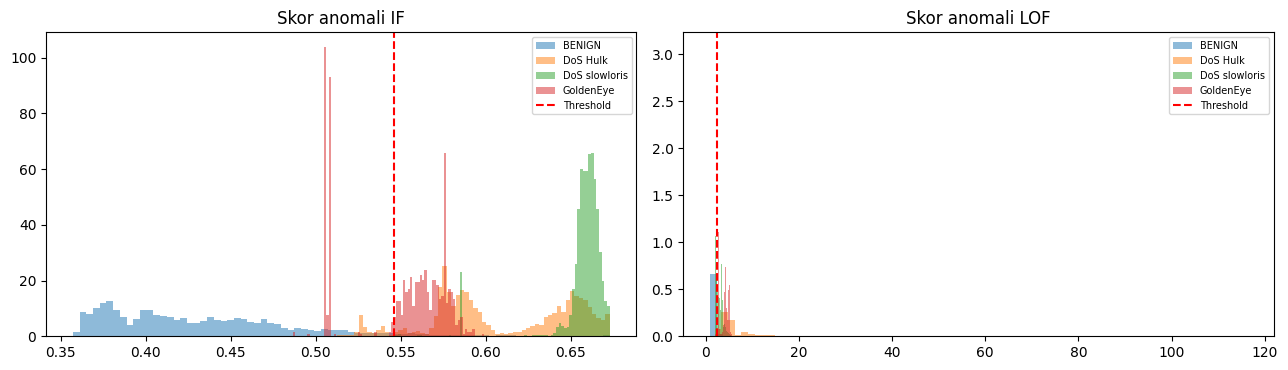

In [26]:
pt_mean = per_type_all.groupby(level=0)[["IF", "LOF"]].mean()
n_uji = pd.Series(LAB_TE[first_extra["tst"]]).value_counts()
pt_mean["n_uji"] = n_uji.reindex(pt_mean.index)
display(pt_mean.sort_values("n_uji", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axes, ["IF", "LOF"]):
    s = first_extra[name]["score"]; lab = first_extra["lab_t"]; hi = np.percentile(s, 99.5)
    for cls in ["BENIGN"] + [c for c in pt_mean.index if pt_mean.loc[c, "n_uji"] >= MIN_TYPE_N]:
        ax.hist(np.clip(s[lab == cls], None, hi), bins=80, alpha=0.5, density=True, label=cls)
    ax.axvline(first_extra[name]["thr"], color="red", ls="--", label="Threshold")
    ax.set_title(f"Skor anomali {name}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Ablasi: pengaruh `Destination_Port`
Dataset ini punya pola port yang menyolok (serangan Hulk dan slowloris selalu ke port 80, jenis lain ke port 30666). Bagian ini mengukur apakah memasukkan port mengubah hasil (satu seed).

In [27]:
rows_p, _, _ = run_seed(SEEDS[0], cols=IDX_WITHPORT, verbose=False)
cmp_cols = ["F1", "PR_AUC", "Macro_Recall_Mayor"]
a = results[(results.seed == SEEDS[0]) & (results.FPR_target == TARGET_FPRS[0])].set_index("Model")[cmp_cols]
b = pd.DataFrame(rows_p); b = b[b.FPR_target == TARGET_FPRS[0]].set_index("Model")[cmp_cols]
display(pd.concat({"tanpa port": a, "dengan port": b}, axis=1).round(3))

tanpa port                           dengan port                          
              F1 PR_AUC Macro_Recall_Mayor          F1 PR_AUC Macro_Recall_Mayor
Model                                                                           
IF         0.954  0.983              0.874       0.975  0.983              0.925
LOF        0.932  0.964              0.897       0.924  0.979              0.882

## 11. Pengaruh representasi fitur pada Isolation Forest

In [28]:
rs = []
for seed in SEEDS[:2]:
    fit, val, tst = make_split(seed)
    Xf, Xv, Xt = (X_TR[fit][:, IDX_NOPORT].astype("float64"), X_TR[val][:, IDX_NOPORT].astype("float64"),
                  X_TE[tst][:, IDX_NOPORT].astype("float64"))
    yv = (LAB_TR[val] != BENIGN_LABEL).astype(int); yt = (LAB_TE[tst] != BENIGN_LABEL).astype(int)
    for tag, tf in [("IF fitur mentah", lambda a: a), ("IF fitur log1p", slog)]:
        m = IsolationForest(n_estimators=200, max_samples=2048, random_state=seed, n_jobs=-1).fit(tf(Xf))
        sv, st = -m.score_samples(tf(Xv)), -m.score_samples(tf(Xt))
        thr = np.percentile(sv[yv == 0], 95)
        rs.append({"model": tag, "seed": seed, "F1": f1_score(yt, st > thr), "ROC_AUC": roc_auc_score(yt, st)})
display(pd.DataFrame(rs).groupby("model")[["F1", "ROC_AUC"]].mean().round(3))
print("Parameter IF dibuat sama (200 pohon, max_samples=2048); satu-satunya beda adalah transformasi log.")

,F1,ROC_AUC
model,,
IF fitur log1p,0.947,0.986
IF fitur mentah,0.517,0.895


Parameter IF dibuat sama (200 pohon, max_samples=2048); satu-satunya beda adalah transformasi log.


## 12. Ringkasan otomatis

In [29]:
m5 = results[results.FPR_target == TARGET_FPRS[0]].groupby("Model")[MAIN].mean()
print(f"Rata-rata {len(SEEDS)} seed, FPR target {TARGET_FPRS[0]:.0%}:")
for c in ["F1", "PR_AUC", "Recall", "Precision", "Macro_Recall_Mayor"]:
    print(f"  - {c:20s}: IF={m5.loc['IF', c]:.3f}  LOF={m5.loc['LOF', c]:.3f}  -> lebih tinggi: {m5[c].idxmax()}")
print(f"  - Waktu prediksi     : IF={m5.loc['IF','Waktu_prediksi_s']:.2f}s  LOF={m5.loc['LOF','Waktu_prediksi_s']:.2f}s")
d = (results[(results.FPR_target == TARGET_FPRS[0]) & (results.Model == 'LOF')].set_index('seed')['F1']
     - results[(results.FPR_target == TARGET_FPRS[0]) & (results.Model == 'IF')].set_index('seed')['F1'])
print(f"\nSelisih F1 (LOF - IF) per seed: {d.round(3).to_dict()}")
print("Jika selisih kecil atau berubah tanda antar seed, jangan menyimpulkan satu model unggul secara meyakinkan.")

Rata-rata 5 seed, FPR target 5%:
  - F1                  : IF=0.955  LOF=0.944  -> lebih tinggi: IF
  - PR_AUC              : IF=0.982  LOF=0.971  -> lebih tinggi: IF
  - Recall              : IF=0.951  LOF=0.931  -> lebih tinggi: IF
  - Precision           : IF=0.960  LOF=0.959  -> lebih tinggi: IF
  - Macro_Recall_Mayor  : IF=0.843  LOF=0.907  -> lebih tinggi: LOF
  - Waktu prediksi     : IF=1.68s  LOF=6.26s

Selisih F1 (LOF - IF) per seed: {42: -0.022, 7: 0.032, 123: 0.014, 2024: -0.08, 99: -0.001}
Jika selisih kecil atau berubah tanda antar seed, jangan menyimpulkan satu model unggul secara meyakinkan.


In [30]:
os.makedirs(OUT_DIR, exist_ok=True)
results.to_csv(f"{OUT_DIR}/hasil_per_seed.csv", index=False)
summary.to_csv(f"{OUT_DIR}/ringkasan_mean_std.csv")
pt_mean.to_csv(f"{OUT_DIR}/recall_per_jenis_serangan.csv")
print("Tersimpan di", OUT_DIR)

Tersimpan di /kaggle/working
